Exploring a graph.

In [1]:
import requests, readline, sys, json
import numpy
import networkx as nx
import matplotlib as mpl
%matplotlib inline
%config InlineBacked.figure_format = 'svg'
import matplotlib.pyplot as plt
import matplotlib.cm as cmap
import seaborn

from query import *
from summary import *


vertexQ is a query to get all vertex labels:

In [2]:
vertexQ

'g.V().label().groupCount()'

getQuery gets the query results, and printResp prints a response

In [3]:
printResp(getQuery(vertexQ))


Response: 200
{'UnitDependency': '489454', 'Event': '489454', 'FileObject': '19907', 'Principal': '2', 'Subject': '35', 'ProvenanceTagNode': '1148'}


getGroupCountQuery runs a query and converts the resulting dictionary to a groupCount

In [4]:
getGroupCountQuery(vertexQ)

Response: 200


[{'Event': 489454,
  'FileObject': 19907,
  'Principal': 2,
  'ProvenanceTagNode': 1148,
  'Subject': 35,
  'UnitDependency': 489454}]

getVertices collects the counts and number of incoming and outgoing edge labels for each vertex label.  For example:

In [5]:
vertices = getVertexSummary()
print (vertices)

Response: 200
Vertex types/counts:
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
{'UnitDependency': {'count': 489454, 'in': {}, 'out': {'unit': 159858, 'dependentUnit': 489454}}, 'Event': {'count': 489454, 'in': {'dependentUnit': 489454}, 'out': {'subject': 159858, 'predicateObject': 23894}}, 'FileObject': {'count': 19907, 'in': {'subject': 1018, 'predicateObject': 23894}, 'out': {}}, 'Principal': {'count': 2, 'in': {'localPrincipal': 35}, 'out': {}}, 'Subject': {'count': 35, 'in': {'unit': 159858, 'parentSubject': 8, 'tagId': 162, 'subject': 159933}, 'out': {'localPrincipal': 35, 'parentSubject': 8}}, 'ProvenanceTagNode': {'count': 1148, 'in': {}, 'out': {'tagId': 162, 'subject': 1093}}}


Likewise, getEdges collects the counts of edge labels and the number of vertex labels on the source and target of each edge.

In [6]:
edges = getEdgeSummary()
print (edges)

Response: 200
Edge types/counts:
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
{'unit': {'count': 159858, 'in': {'Subject': 159858}, 'out': {'UnitDependency': 159858}}, 'localPrincipal': {'count': 35, 'in': {'Principal': 35}, 'out': {'Subject': 35}}, 'parentSubject': {'count': 8, 'in': {'Subject': 8}, 'out': {'Subject': 8}}, 'tagId': {'count': 162, 'in': {'Subject': 162}, 'out': {'ProvenanceTagNode': 162}}, 'subject': {'count': 160951, 'in': {'FileObject': 1018, 'Subject': 159933}, 'out': {'Event': 159858, 'ProvenanceTagNode': 1093}}, 'predicateObject': {'count': 23894, 'in': {'FileObject': 23894}, 'out': {'Event': 23894}}, 'dependentUnit': {'count': 489454, 'in': {'Event': 489454}, 'out': {'UnitDependency': 489454}}}


Hmm.  Not very readable.  Let's try to do better.  printSummary takes a dictionary in one of the above forms and prints out the results in a more structured way.

In [7]:
printSummary(vertices)

{}
 -> 
UnitDependency[489454]
 -> 
{unit[159858],
dependentUnit[489454]}

{dependentUnit[489454]}
 -> 
Event[489454]
 -> 
{subject[159858],
predicateObject[23894]}

{subject[1018],
predicateObject[23894]}
 -> 
FileObject[19907]
 -> 
{}

{localPrincipal[35]}
 -> 
Principal[2]
 -> 
{}

{unit[159858],
parentSubject[8],
tagId[162],
subject[159933]}
 -> 
Subject[35]
 -> 
{localPrincipal[35],
parentSubject[8]}

{}
 -> 
ProvenanceTagNode[1148]
 -> 
{tagId[162],
subject[1093]}



How about for edges?

In [8]:
printSummary(edges)

{Subject[159858]}
 -> 
unit[159858]
 -> 
{UnitDependency[159858]}

{Principal[35]}
 -> 
localPrincipal[35]
 -> 
{Subject[35]}

{Subject[8]}
 -> 
parentSubject[8]
 -> 
{Subject[8]}

{Subject[162]}
 -> 
tagId[162]
 -> 
{ProvenanceTagNode[162]}

{FileObject[1018],
Subject[159933]}
 -> 
subject[160951]
 -> 
{Event[159858],
ProvenanceTagNode[1093]}

{FileObject[23894]}
 -> 
predicateObject[23894]
 -> 
{Event[23894]}

{Event[489454]}
 -> 
dependentUnit[489454]
 -> 
{UnitDependency[489454]}



Now let's build and visualize a (bipartite) graph.  Nodes will represent either node or edge labels, and edges represent that a node can have an in-edge or out-edge with a given label (or vice versa).

In [9]:
G = nx.DiGraph()


In [10]:
G.add_nodes_from(vertices,bipartite=0)
G.add_nodes_from(edges,bipartite=1)

In [11]:
for v in vertices.keys():
    for e in vertices[v]['in'].keys():
        G.add_edge(e,v)
    for e in vertices[v]['out'].keys():
        G.add_edge(v,e)

In [12]:
nx.is_bipartite(G)

True

In [13]:
from networkx.algorithms import bipartite
bottom_nodes, top_nodes = bipartite.sets(G)
bottom_nodes,top_nodes

({'Event',
  'FileObject',
  'Principal',
  'ProvenanceTagNode',
  'Subject',
  'UnitDependency'},
 {'dependentUnit',
  'localPrincipal',
  'parentSubject',
  'predicateObject',
  'subject',
  'tagId',
  'unit'})

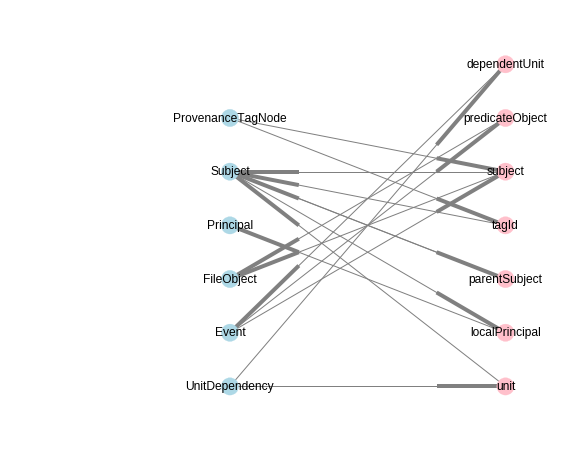

In [14]:
def showBiGraph(G):
    colors = ['lightblue' if d['bipartite']==0 else 'pink' for x,d in G.nodes(data=True)]
    positions = {}
    i = 1
    j = 1
    for x,d in G.nodes(data=True):
        if d['bipartite'] == 0:
            positions[x] = (3,i)
            i = i + 1
        else:
            positions[x] = (7,j)
            j = j + 1
    height = max(i,j)
    fig = plt.figure(figsize=(10,height))
    plt.gca().set_axis_off()   
    plt.gca().set_xlim([-0.05, height+0.05])    # add a little space around the plot
    plt.gca().set_ylim([-0.05, height+0.05])

    nx.draw_networkx(G,pos=positions,
                   with_labels=True,node_color=colors,edge_color='gray')

    _ = plt.show()

showBiGraph(G)

Consider the edge labels into and out of each node type and abstract them as +, *, 1, or ?

In [15]:
summarizeIncidences('Event')

Response: 200
Response: 200


{'in': {'dependentUnit': '1'}, 'out': {'predicateObject': '?', 'subject': '?'}}

In [16]:

schema = inferSchema(vertices.keys())
schema

Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200
Response: 200


{'Event': {'in': {'dependentUnit': '1'},
  'out': {'predicateObject': '?', 'subject': '?'}},
 'FileObject': {'in': {'predicateObject': '*', 'subject': '?'}, 'out': {}},
 'Principal': {'in': {'localPrincipal': '+'}, 'out': {}},
 'ProvenanceTagNode': {'in': {}, 'out': {'subject': '?', 'tagId': '*'}},
 'Subject': {'in': {'parentSubject': '*',
   'subject': '+',
   'tagId': '*',
   'unit': '*'},
  'out': {'localPrincipal': '1', 'parentSubject': '?'}},
 'UnitDependency': {'in': {}, 'out': {'dependentUnit': '1', 'unit': '?'}}}

A _rigid path_ is a path that follows only edges with multiplicity <= 1.  Edges can be traversed in either direction but should not be traversed twice.  Rigid paths are useful for exploring because it does no harm to follow them.

In [17]:
def multLeq1(edges):
    return {label for label in edges.keys() if edges[label]== '1' or edges[label] == '?'}

def schemaMultLeq1(schema):
    return {label : {'in': multLeq1(schema[label]['in']), 'out':multLeq1(schema[label]['out'])}
             for label in schema.keys()}
            
schemaMultLeq1(schema)
            

{'Event': {'in': {'dependentUnit'}, 'out': {'predicateObject', 'subject'}},
 'FileObject': {'in': {'subject'}, 'out': set()},
 'Principal': {'in': set(), 'out': set()},
 'ProvenanceTagNode': {'in': set(), 'out': {'subject'}},
 'Subject': {'in': set(), 'out': {'localPrincipal', 'parentSubject'}},
 'UnitDependency': {'in': set(), 'out': {'dependentUnit', 'unit'}}}